In [3]:
#Load the data

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

sns.set_theme(style='whitegrid')
os.makedirs('../outputs', exist_ok=True)

enso = pd.read_csv('../data/enso_clean.csv', parse_dates=['date'])
enso = enso[['date', 'oni', 'soi']].sort_values('date').reset_index(drop=True)

gaps = enso['date'].diff().dropna().dt.days
print(enso.shape)
print('Days between rows, min and max:', gaps.min(), gaps.max())
print(enso.tail(3))

(908, 3)
Days between rows, min and max: 28 31
          date   oni  soi
905 2026-06-01  1.39 -2.4
906 2026-07-01  1.80 -4.0
907 2026-08-01  2.16 -1.8


In [6]:
# Build forecasting setup

lags = [0, 1, 2, 3, 6]          # how many months back to look
horizons = [1, 2, 3, 6]         # how many months ahead to predict
split_date = pd.Timestamp('2005-12-01')   # training targets end here

feature_cols = (
    [f'oni_lag{k}' for k in lags]
    + [f'soi_lag{k}' for k in lags]
    + ['month_sin', 'month_cos']
)

def make_dataset(df, h):
    d = df.copy()
    for k in lags:
        d[f'oni_lag{k}'] = d['oni'].shift(k)
        d[f'soi_lag{k}'] = d['soi'].shift(k)
    # Month of year as a circle, so December and January are neighbours
    d['month_sin'] = np.sin(2 * np.pi * d['date'].dt.month / 12)
    d['month_cos'] = np.cos(2 * np.pi * d['date'].dt.month / 12)
    d['target'] = d['oni'].shift(-h)
    d['target_date'] = d['date'] + pd.DateOffset(months=h)
    return d

def label(x):
    x = np.asarray(x)
    return np.select([x >= 0.5, x <= -0.5], ['El Niño', 'La Niña'], default='Neutral')

def score(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    acc = (label(y_true) == label(y_pred)).mean()
    return mae, rmse, acc

d3 = make_dataset(enso, 3)
d3[['date', 'oni', 'oni_lag1', 'target', 'target_date']].iloc[6:10]


,date,oni,oni_lag1,target,target_date
6,1951-07-01,0.71,0.50,1.03,1951-10-01
7,1951-08-01,0.90,0.71,0.96,1951-11-01
8,1951-09-01,1.02,0.90,0.71,1951-12-01
9,1951-10-01,1.03,1.02,0.52,1952-01-01


In [7]:
# Split by time

d3 = d3.dropna(subset=feature_cols + ['target'])
train3 = d3[d3['target_date'] <= split_date]
test3 = d3[d3['date'] > split_date]

print('Train rows:', len(train3), ' Test rows:', len(test3))
print('Train origins:', train3['date'].min().date(), 'to', train3['date'].max().date())
print('Test origins: ', test3['date'].min().date(), 'to', test3['date'].max().date())

Train rows: 651  Test rows: 245
Train origins: 1951-07-01 to 2005-09-01
Test origins:  2006-01-01 to 2026-05-01


In [8]:
# Train and compare the models

results = []
store = {}

for h in horizons:
    d = make_dataset(enso, h).dropna(subset=feature_cols + ['target'])
    train = d[d['target_date'] <= split_date]
    test = d[d['date'] > split_date]
    X_train, y_train = train[feature_cols], train['target']
    X_test, y_test = test[feature_cols], test['target']

    preds = {
        'Persistence': X_test['oni_lag0'].values,
        'Training mean': np.full(len(y_test), y_train.mean()),
    }
    preds['Linear regression'] = LinearRegression().fit(X_train, y_train).predict(X_test)

    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1)
    preds['Random forest'] = rf.fit(X_train, y_train).predict(X_test)

    for name, p in preds.items():
        mae, rmse, acc = score(y_test, p)
        results.append({'horizon': h, 'model': name, 'mae': mae, 'rmse': rmse, 'phase_accuracy': acc})

    store[h] = {'test': test, 'preds': preds, 'rf': rf}

results = pd.DataFrame(results)
mae_table = results.pivot(index='horizon', columns='model', values='mae')
print('MAE (average miss in ONI units, lower is better):')
print(mae_table.round(3))

MAE (average miss in ONI units, lower is better):
model    Linear regression  Persistence  Random forest  Training mean
horizon                                                              
1                    0.078        0.171          0.123          0.677
2                    0.187        0.327          0.230          0.676
3                    0.309        0.466          0.337          0.676
6                    0.563        0.764          0.564          0.681


In [9]:
# How much better than persistence

skill = pd.DataFrame({
    'Linear regression': (1 - mae_table['Linear regression'] / mae_table['Persistence']) * 100,
    'Random forest': (1 - mae_table['Random forest'] / mae_table['Persistence']) * 100,
}).round(1)
print('Percent lower error than persistence (negative = worse):')
print(skill)
print()

acc_table = results.pivot(index='horizon', columns='model', values='phase_accuracy')
print('How often the predicted phase was right:')
print((acc_table * 100).round(1))

Percent lower error than persistence (negative = worse):
         Linear regression  Random forest
horizon                                  
1                     54.3           28.1
2                     42.8           29.6
3                     33.6           27.6
6                     26.3           26.2

How often the predicted phase was right:
model    Linear regression  Persistence  Random forest  Training mean
horizon                                                              
1                     96.0         87.0           91.9           44.9
2                     85.4         74.8           83.7           45.1
3                     75.1         63.7           71.8           45.3
6                     53.3         47.1           51.2           44.6


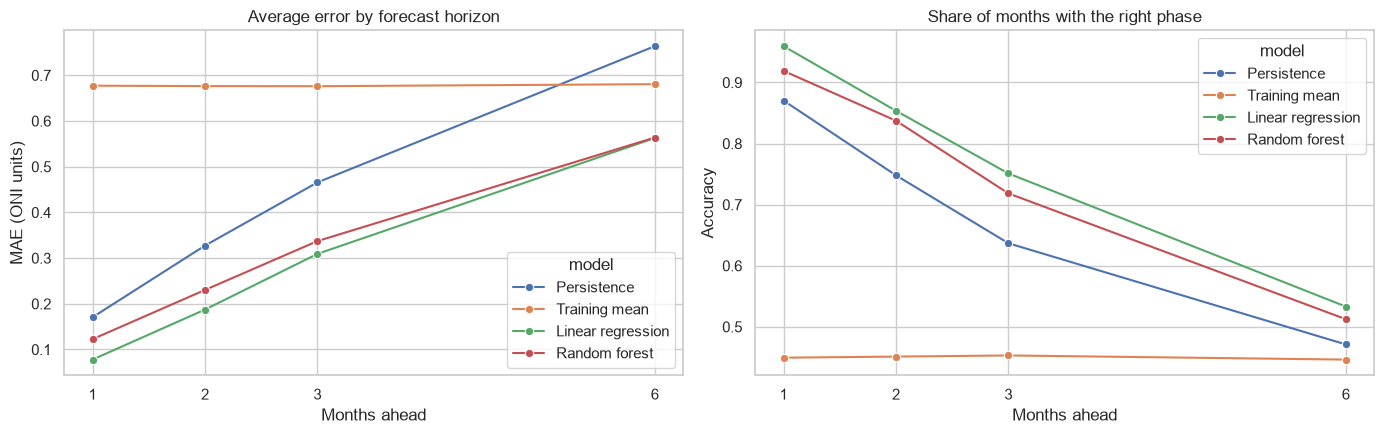

In [11]:
# plots

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

sns.lineplot(data=results, x='horizon', y='mae', hue='model', marker='o', ax=ax[0])
ax[0].set_title('Average error by forecast horizon')
ax[0].set_xlabel('Months ahead')
ax[0].set_ylabel('MAE (ONI units)')
ax[0].set_xticks(horizons)

sns.lineplot(data=results, x='horizon', y='phase_accuracy', hue='model', marker='o', ax=ax[1])
ax[1].set_title('Share of months with the right phase')
ax[1].set_xlabel('Months ahead')
ax[1].set_ylabel('Accuracy')
ax[1].set_xticks(horizons)

plt.tight_layout()
plt.savefig('../outputs/fig08_horizon_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

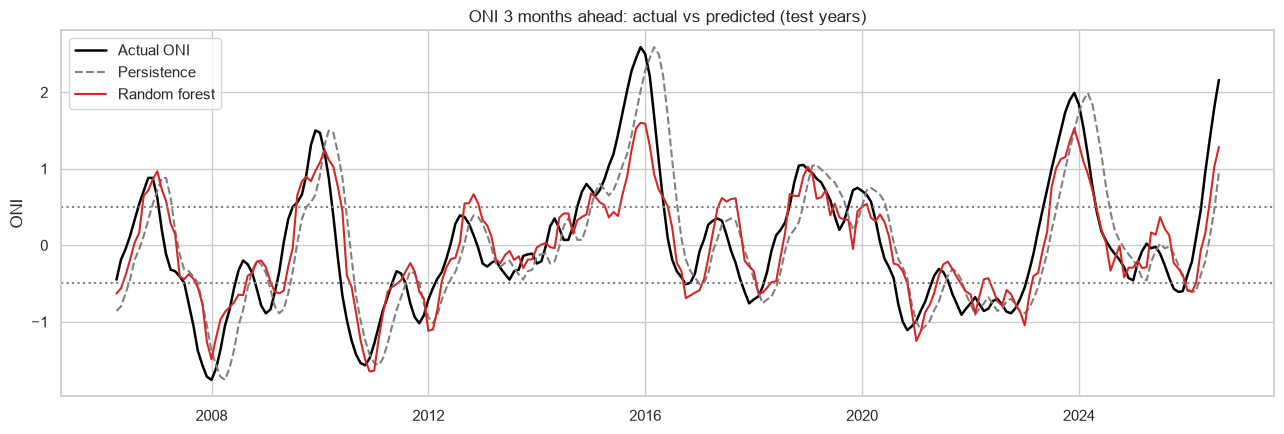

In [12]:
# 

test3 = store[3]['test']
p3 = store[3]['preds']

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(test3['target_date'], test3['target'], color='black', lw=1.8, label='Actual ONI')
ax.plot(test3['target_date'], p3['Persistence'], color='gray', ls='--', label='Persistence')
ax.plot(test3['target_date'], p3['Random forest'], color='tab:red', label='Random forest')
ax.axhline(0.5, ls=':', color='gray')
ax.axhline(-0.5, ls=':', color='gray')
ax.set_title('ONI 3 months ahead: actual vs predicted (test years)')
ax.set_ylabel('ONI')
ax.legend()
plt.tight_layout()
plt.savefig('../outputs/fig09_forecast_3month.png', dpi=150, bbox_inches='tight')
plt.show()

      persistence_err  rf_err
date                         
1                0.56    0.27
2                0.63    0.33
3                0.62    0.36
4                0.57    0.36
5                0.49    0.35
6                0.43    0.36
7                0.45    0.35
8                0.48    0.40
9                0.38    0.33
10               0.25    0.35
11               0.27    0.30
12               0.43    0.29


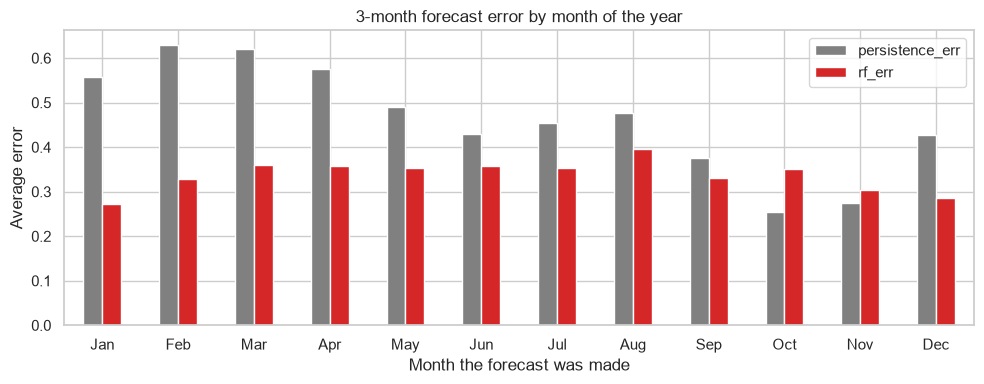

In [13]:
# where do models fail
# By time of the year

t3 = store[3]['test'].copy()
t3['persistence_err'] = (t3['target'] - store[3]['preds']['Persistence']).abs()
t3['rf_err'] = (t3['target'] - store[3]['preds']['Random forest']).abs()

by_month = t3.groupby(t3['date'].dt.month)[['persistence_err', 'rf_err']].mean()
print(by_month.round(2))

ax = by_month.plot(kind='bar', figsize=(10, 4), rot=0, color=['gray', 'tab:red'])
ax.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
ax.set_xlabel('Month the forecast was made')
ax.set_ylabel('Average error')
ax.set_title('3-month forecast error by month of the year')
plt.tight_layout()
plt.savefig('../outputs/fig10_error_by_month.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
# The biggest misses

t3['rf_pred'] = store[3]['preds']['Random forest']
t3['rf_abs_err'] = (t3['target'] - t3['rf_pred']).abs()

misses = t3.nlargest(10, 'rf_abs_err')[['date', 'target_date', 'target', 'rf_pred', 'rf_abs_err']].round(2)
print(misses)

          date target_date  target  rf_pred  rf_abs_err
773 2015-06-01  2015-09-01    2.02     0.90        1.12
710 2010-03-01  2010-06-01   -0.66     0.45        1.11
772 2015-05-01  2015-08-01    1.73     0.66        1.07
771 2015-04-01  2015-07-01    1.44     0.38        1.06
774 2015-07-01  2015-10-01    2.28     1.25        1.03
776 2015-09-01  2015-12-01    2.59     1.60        0.99
709 2010-02-01  2010-05-01   -0.16     0.77        0.93
775 2015-08-01  2015-11-01    2.45     1.53        0.92
778 2015-11-01  2016-02-01    2.21     1.30        0.91
777 2015-10-01  2016-01-01    2.50     1.59        0.91


C:\Users\DELL\AppData\Local\Temp\ipykernel_4200\3649362387.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  misses = t3.nlargest(10, 'rf_abs_err')[['date', 'target_date', 'target', 'rf_pred', 'rf_abs_err']].round(2)


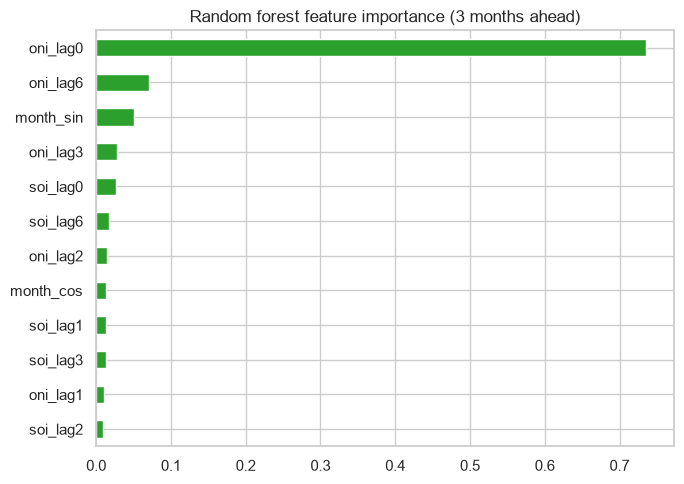

In [15]:
# What the random firest relied on

imp = pd.Series(store[3]['rf'].feature_importances_, index=feature_cols).sort_values()
ax = imp.plot(kind='barh', figsize=(7, 5), color='tab:green')
ax.set_title('Random forest feature importance (3 months ahead)')
plt.tight_layout()
plt.savefig('../outputs/fig11_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

In [16]:
# Result to current El nino

rows = []
for h in horizons:
    d = make_dataset(enso, h)
    full = d.dropna(subset=feature_cols + ['target'])
    last = d.iloc[[-1]]

    lin_full = LinearRegression().fit(full[feature_cols], full['target'])
    rf_full = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1)
    rf_full.fit(full[feature_cols], full['target'])

    for_month = (last['date'].iloc[0] + pd.DateOffset(months=h)).strftime('%Y-%m')
    rows.append({
        'months_ahead': h,
        'for_month': for_month,
        'persistence': round(last['oni_lag0'].iloc[0], 2),
        'linear': round(lin_full.predict(last[feature_cols])[0], 2),
        'random_forest': round(rf_full.predict(last[feature_cols])[0], 2),
    })

current = pd.DataFrame(rows)
print(current)

   months_ahead for_month  persistence  linear  random_forest
0             1   2026-09         2.16    2.32           2.18
1             2   2026-10         2.16    2.32           2.16
2             3   2026-11         2.16    2.19           1.94
3             6   2027-02         2.16    1.49           1.23


In [17]:
results.round(3).to_csv('../outputs/forecast_results.csv', index=False)
current.to_csv('../outputs/forecast_current.csv', index=False)
print(os.listdir('../outputs'))

['enso_events.csv', 'fig01_distributions.png', 'fig02_event_timeline.png', 'fig03_by_decade.png', 'fig04_peak_month.png', 'fig05_oni_vs_soi.png', 'fig06_lag_correlation.png', 'fig07_long_term.png', 'fig08_horizon_comparison.png', 'fig09_forecast_3month.png', 'fig10_error_by_month.png', 'fig11_feature_importance.png', 'forecast_current.csv', 'forecast_results.csv', 'phase_summary.csv']


## Forecasting findings

**Setup**
I tried to predict the ONI 1, 2, 3 and 6 months ahead from past ONI and SOI values and the month of the year. I trained on 1951 to 2005 and tested on 2006 to 2026 with a time-based split, so no future data leaked in. I compared linear regression and a random forest with two baselines: persistence (the future looks like now) and the training mean.

**Results**
- Persistence error (MAE) grew from 0.171 at 1 month to 0.764 at 6 months. The training mean stayed flat at about 0.68, because it ignores current conditions.
- Both models beat persistence at every horizon. Linear regression had 54%, 43%, 34% and 26% lower error at 1, 2, 3 and 6 months. The random forest had 28%, 30%, 28% and 26%.
- Linear regression was the best model at 1 to 3 months (MAE 0.078, 0.187 and 0.309), and the two models tied at 6 months (0.563 vs 0.564). The simpler model beat the random forest, likely because there are only about 650 training months.
- Part of the short-range skill is momentum: the lagged values show which way the ONI is moving, while persistence assumes it stands still.
- Skill fades with distance. At 6 months the models' error is only about 17% below the training mean.
- The predicted phase (El Niño, La Niña or Neutral) was right 96.0% of the time at 1 month with linear regression, 75.1% at 3 months and 53.3% at 6 months. Persistence got 87.0%, 63.7% and 47.1%. At 6 months a guess near the average still got 44.6%, so the gain from the models is modest.

**Where it fails**
- Time of year: persistence was worst for forecasts made in February to April (error 0.57 to 0.63), which shows the spring predictability barrier clearly. The random forest cut the error most in January to April, by roughly 40 to 50%, and its error was fairly flat through the year (0.27 to 0.40, highest in August).
- In October and November persistence actually beat the random forest (0.25 and 0.27 vs 0.35 and 0.30). Events are usually near their peak then, so little changes over 3 months.
- The ten largest misses of the random forest came from two episodes. Eight were forecasts made during the rapid growth of the 2015-16 El Niño, where it predicted 0.4 to 1.6 when the real ONI reached 1.4 to 2.6. Two were from early 2010, when it missed a quick flip from El Niño to La Niña. The model struggles when an event grows quickly or reverses suddenly, and a random forest cannot predict above the values it saw in training.
- The random forest relied mostly on the latest ONI value (about 73% of importance), followed by the ONI 6 months earlier (about 7%) and the month of the year (about 5%). All SOI features together came to under 10%, consistent with the lag analysis in Step 3: SOI moves with ONI rather than leading it.

**Current El Niño**
From August 2026 data (ONI +2.16), both models expect the El Niño to continue. Linear regression predicts +2.32 for September and October 2026, +2.19 for November and +1.49 for February 2027. The random forest predicts +2.18, +2.16, +1.94 and +1.23. So both see it staying strong through the autumn and weakening by early 2027 while remaining above the El Niño threshold. The gap between the models at 6 months shows hown official forecast.

**Limitations**
- Only about 900 monthly rows and a handful of events. The test period includes only a few big events, so one event (2015-16) drives most of the largest errors.
- Only ONI and SOI are used. Real forecasts add subsurface ocean heat, winds and physics-based models.
- Hyperparameters were not tuned.
- Part of the short-range skill reflects the 3-month averaging in the ONI.
- Phase accuracy uses the plus and minus 0.5 thresholds, so months near the line can flip easily.